In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve, auc, recall_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier

In [3]:
airports = pd.read_csv("airports.csv")
flights = pd.read_csv("flights.csv")
planes = pd.read_csv("planes.csv")
weather = pd.read_csv("weather.csv")

In [4]:
data = (
    flights
    .merge(planes, left_on="tailnum", right_on="tailnum", how="left")
    .merge(airports, left_on="origin", right_on="faa", how="left", suffixes=("_origin", "_dest"))
    .merge(airports, left_on="dest", right_on="faa", how="left", suffixes=("_origin", "_dest"))
    .merge(airports, left_on="dest", right_on="faa", how="left", suffixes=("_origin", "_dest"))
)   
data.to_csv("data.csv", index=False)

In [5]:
# Merge data with weather information at origin
data_with_weather = data.merge(
    weather, 
    left_on=["year_x", "month", "day", "hour"], 
    right_on=["year", "month", "day", "hour"],
    how="left",
    suffixes=("", "_weather_origin")
)

# Rename weather columns for clarity
data_with_weather = data_with_weather.rename(columns={
    "temp": "temp_origin",
    "dewp": "dewp_origin",
    "humid": "humid_origin",
    "wind_dir": "wind_dir_origin",
    "wind_speed": "wind_speed_origin",
    "wind_gust": "wind_gust_origin",
    "precip": "precip_origin",
    "pressure": "pressure_origin",
    "visib": "visib_origin"
})

# Drop duplicate time_hour column from weather merge
data_with_weather = data_with_weather.drop(columns=["time_hour_weather_origin", "year", "origin_weather_origin"], errors="ignore")

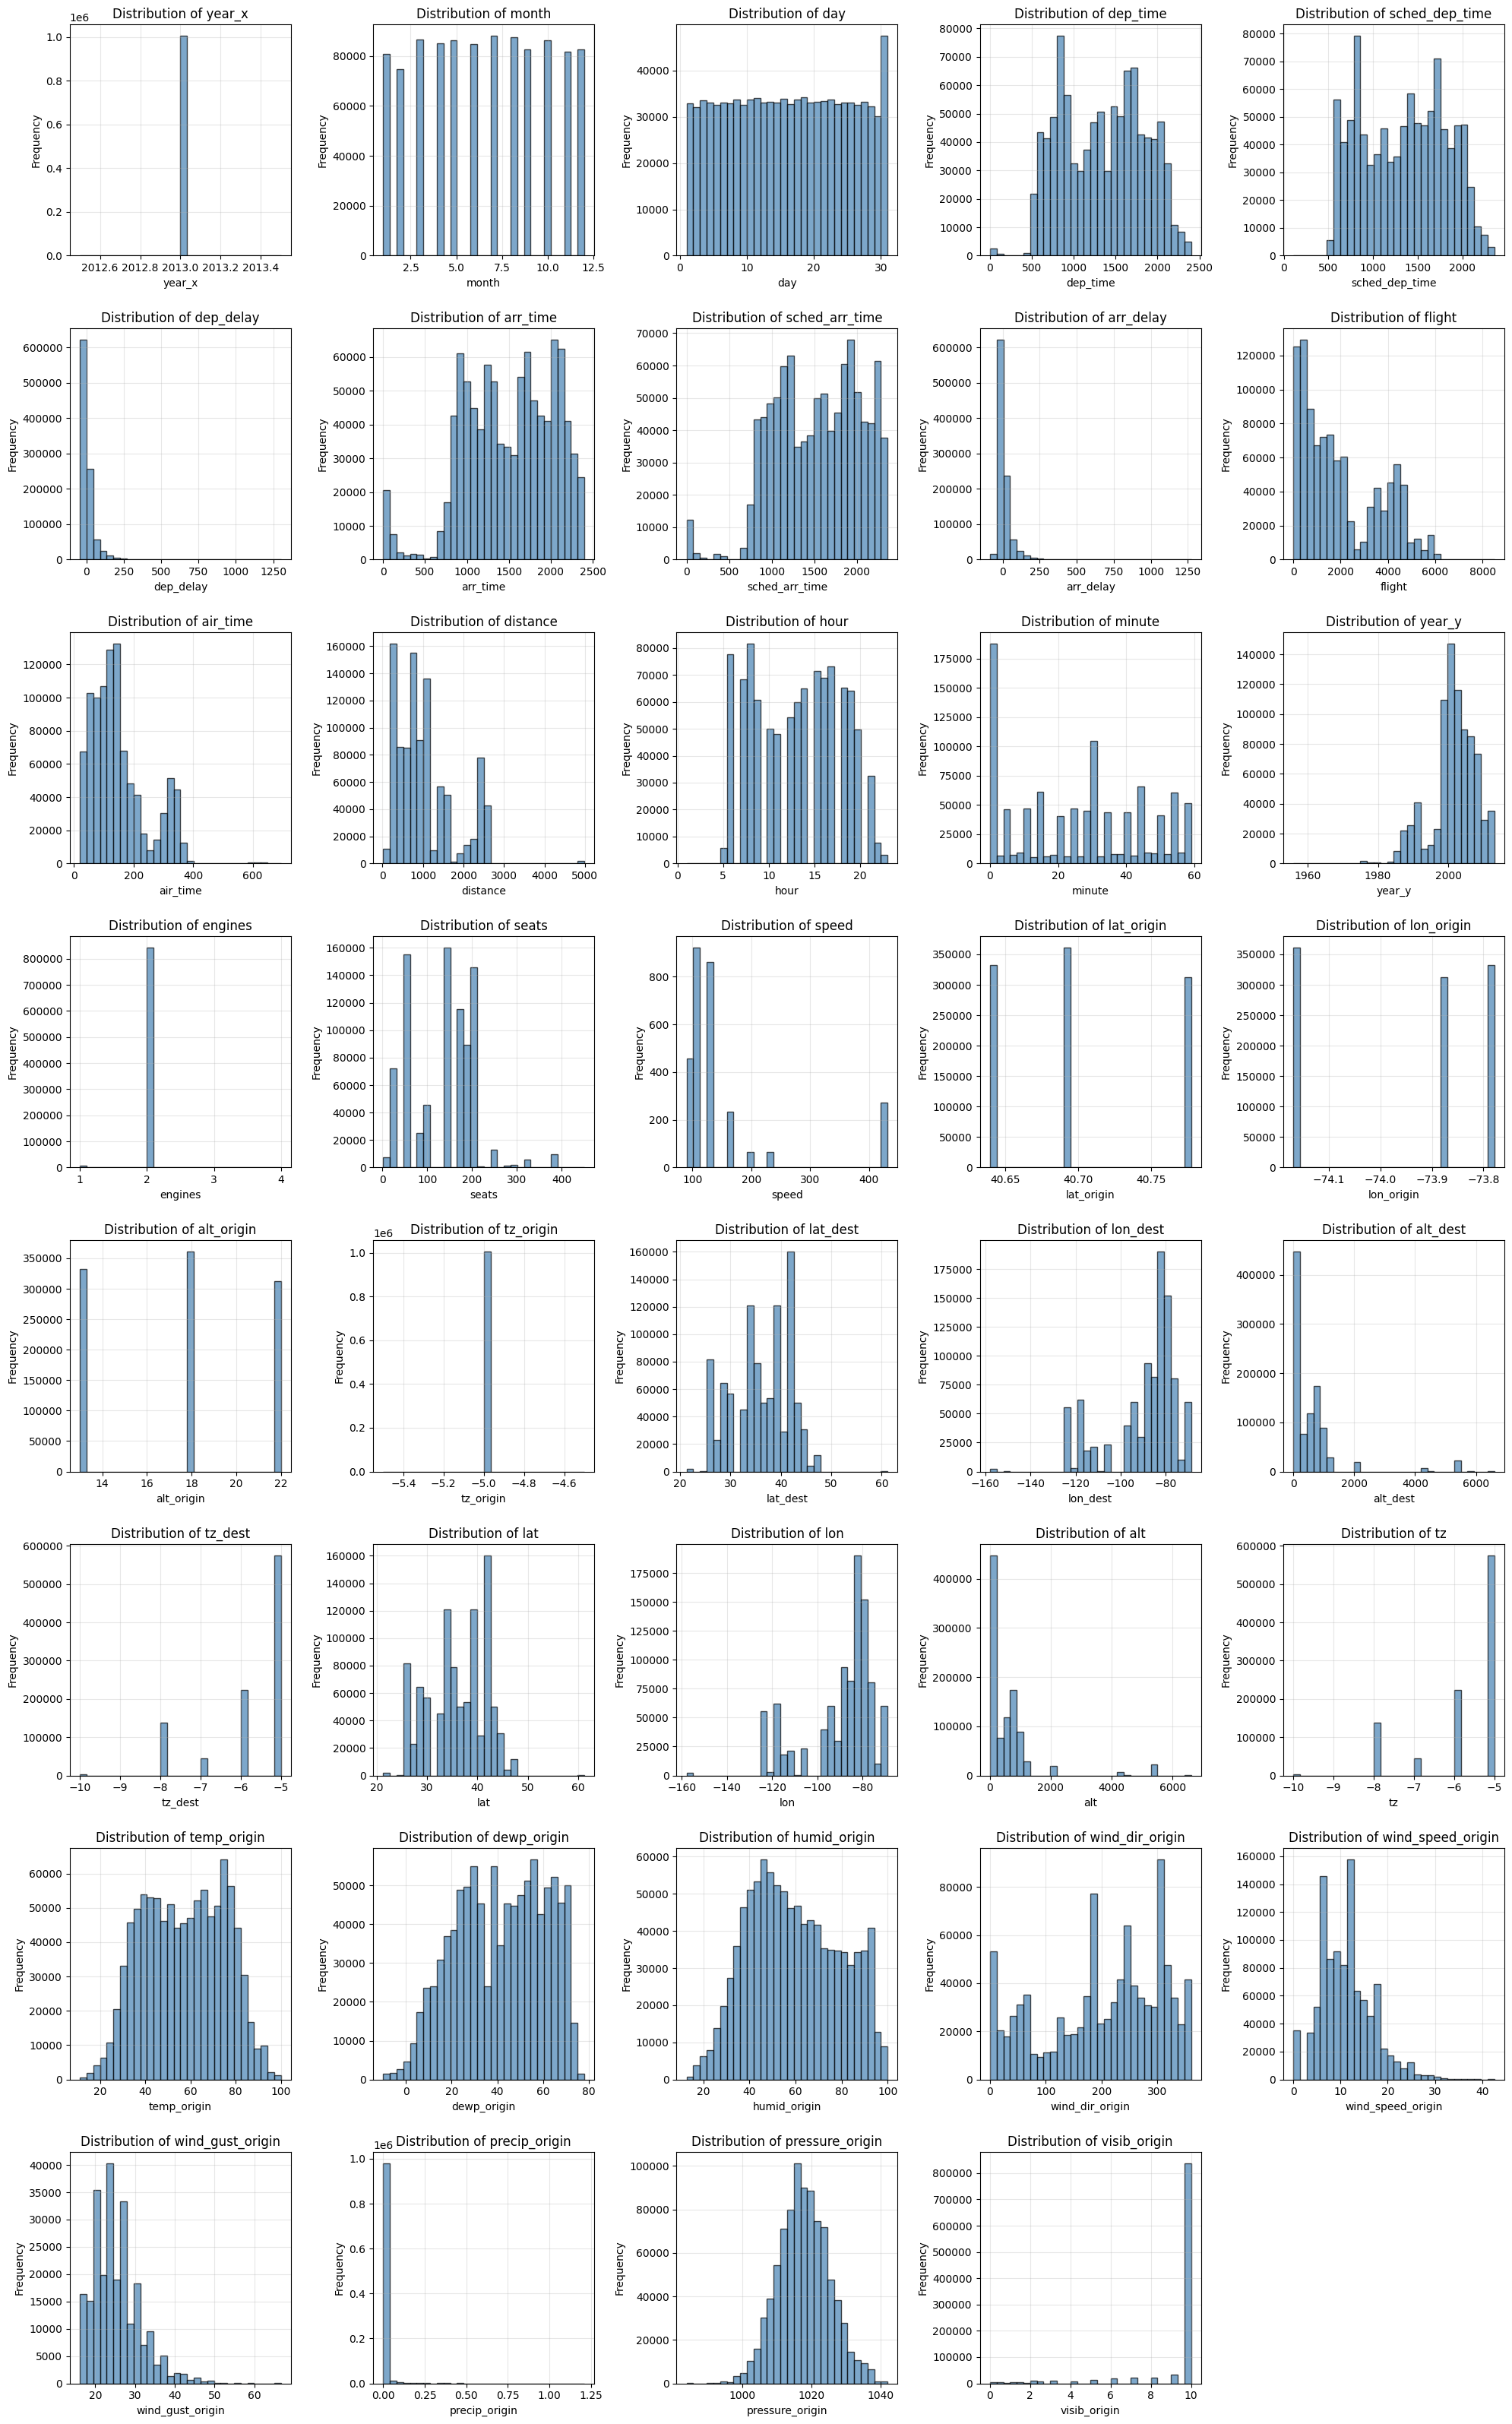

In [6]:
# Create distribution plots for all features
numeric_features_list = data_with_weather.select_dtypes(include=['float64', 'int64']).columns.tolist()
n_features = len(numeric_features_list)
n_cols = 5
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4*n_rows))
axes = axes.flatten()

for idx, feature in enumerate(numeric_features_list):
    axes[idx].hist(data_with_weather[feature], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[idx].set_title(f'Distribution of {feature}')
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel('Frequency')
    axes[idx].grid(True, alpha=0.3)

# Hide empty subplots
for idx in range(n_features, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

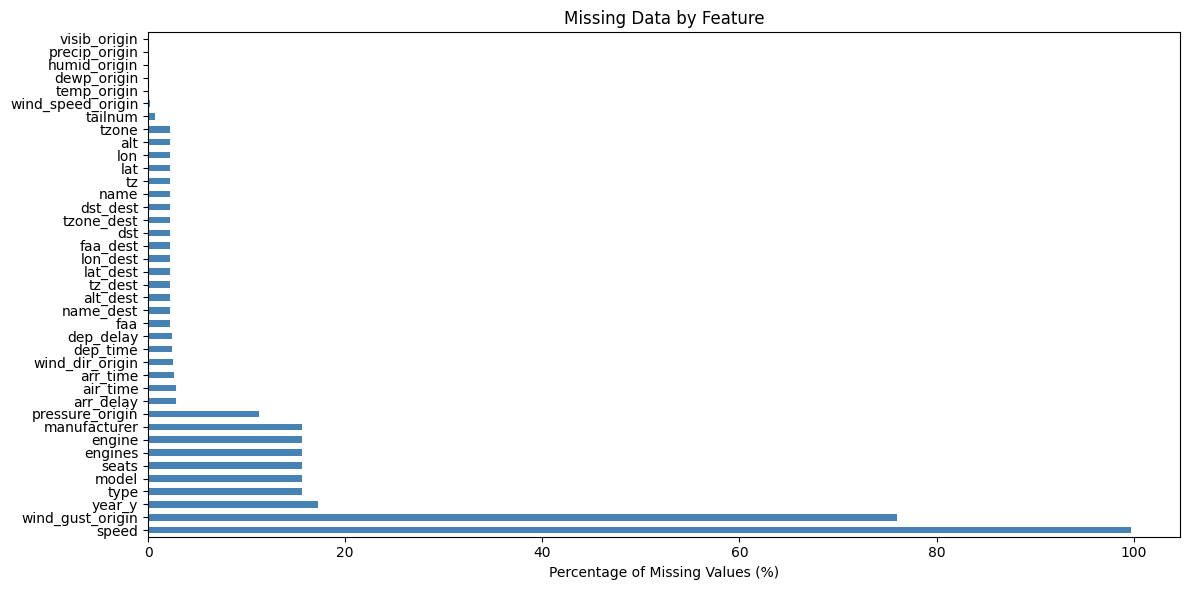

In [7]:
# Create a missingingness plot
missing_data = data_with_weather.isnull().sum()
missing_percent = (missing_data / len(data_with_weather)) * 100

# Filter columns with missing values
missing_filtered = missing_percent[missing_percent > 0].sort_values(ascending=False)

# Create the plot
fig, ax = plt.subplots(figsize=(12, 6))
missing_filtered.plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Percentage of Missing Values (%)')
ax.set_title('Missing Data by Feature')
plt.tight_layout()
plt.show()

In [8]:
# Remove speed and wind_gust columns, then drop all null values
data_with_weather = data_with_weather.drop(columns=['speed', 'wind_gust_origin','air_time','arr_time','tz_orgin','year_x','dep_time','dep_delay'], errors='ignore')
data_with_weather = data_with_weather.dropna()

In [9]:
# add binary delay flag: 1 if arrival delay > 15 minutes, else 0~
data_with_weather['delay_binary'] = (data_with_weather['arr_delay'] > 15).astype(int)
data_with_weather = data_with_weather.drop(columns=['arr_delay'], errors='ignore')

In [10]:


summary = pd.DataFrame({
    "Feature": data_with_weather.columns,
    "Type": data_with_weather.dtypes.values,
    "Non-null count": data_with_weather.count().values
})

summary

,Feature,Type,Non-null count
0,month,int64,698440
1,day,int64,698440
2,sched_dep_time,int64,698440
3,sched_arr_time,int64,698440
4,carrier,str,698440
5,flight,int64,698440
6,tailnum,str,698440
7,origin,str,698440
8,dest,str,698440
9,distance,int64,698440


In [13]:
# prepare features and target
X = data_with_weather.drop(columns=['delay_binary'])
y = data_with_weather['delay_binary']

# prepare numeric features and target, then do stratified train/test split
numeric_cols = data_with_weather.select_dtypes(include=[np.number]).columns.tolist()
if 'delay_binary' in numeric_cols:
    numeric_cols.remove('delay_binary')

X = data_with_weather[numeric_cols]
y = data_with_weather['delay_binary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "X_test:", X_test.shape, "y_train:", y_train.shape, "y_test:", y_test.shape)
X_train.head()

X_train: (558752, 31) X_test: (139688, 31) y_train: (558752,) y_test: (139688,)


,month,day,sched_dep_time,sched_arr_time,flight,distance,hour,minute,year_y,engines,...,alt,tz,temp_origin,dewp_origin,humid_origin,wind_dir_origin,wind_speed_origin,precip_origin,pressure_origin,visib_origin
386397,2,21,1857,2157,248,1023,18,57,1994.0,2.0,...,19.0,-5.0,28.94,12.02,48.69,320.0,17.26170,0.0,1020.9,10.0
773701,7,10,752,953,4104,628,7,52,2002.0,2.0,...,45.0,-5.0,78.08,69.98,76.19,180.0,8.05546,0.0,1014.4,8.0
946446,9,9,1005,1214,2319,1020,10,5,1991.0,2.0,...,841.0,-6.0,66.92,46.04,46.98,30.0,8.05546,0.0,1024.1,10.0
647241,5,26,635,904,1743,760,6,35,1989.0,2.0,...,1026.0,-5.0,51.08,37.94,60.60,260.0,13.80936,0.0,1016.7,10.0
621021,5,16,1435,1710,615,828,14,35,2010.0,2.0,...,30.0,-5.0,78.98,48.02,33.70,210.0,13.80936,0.0,1007.5,10.0


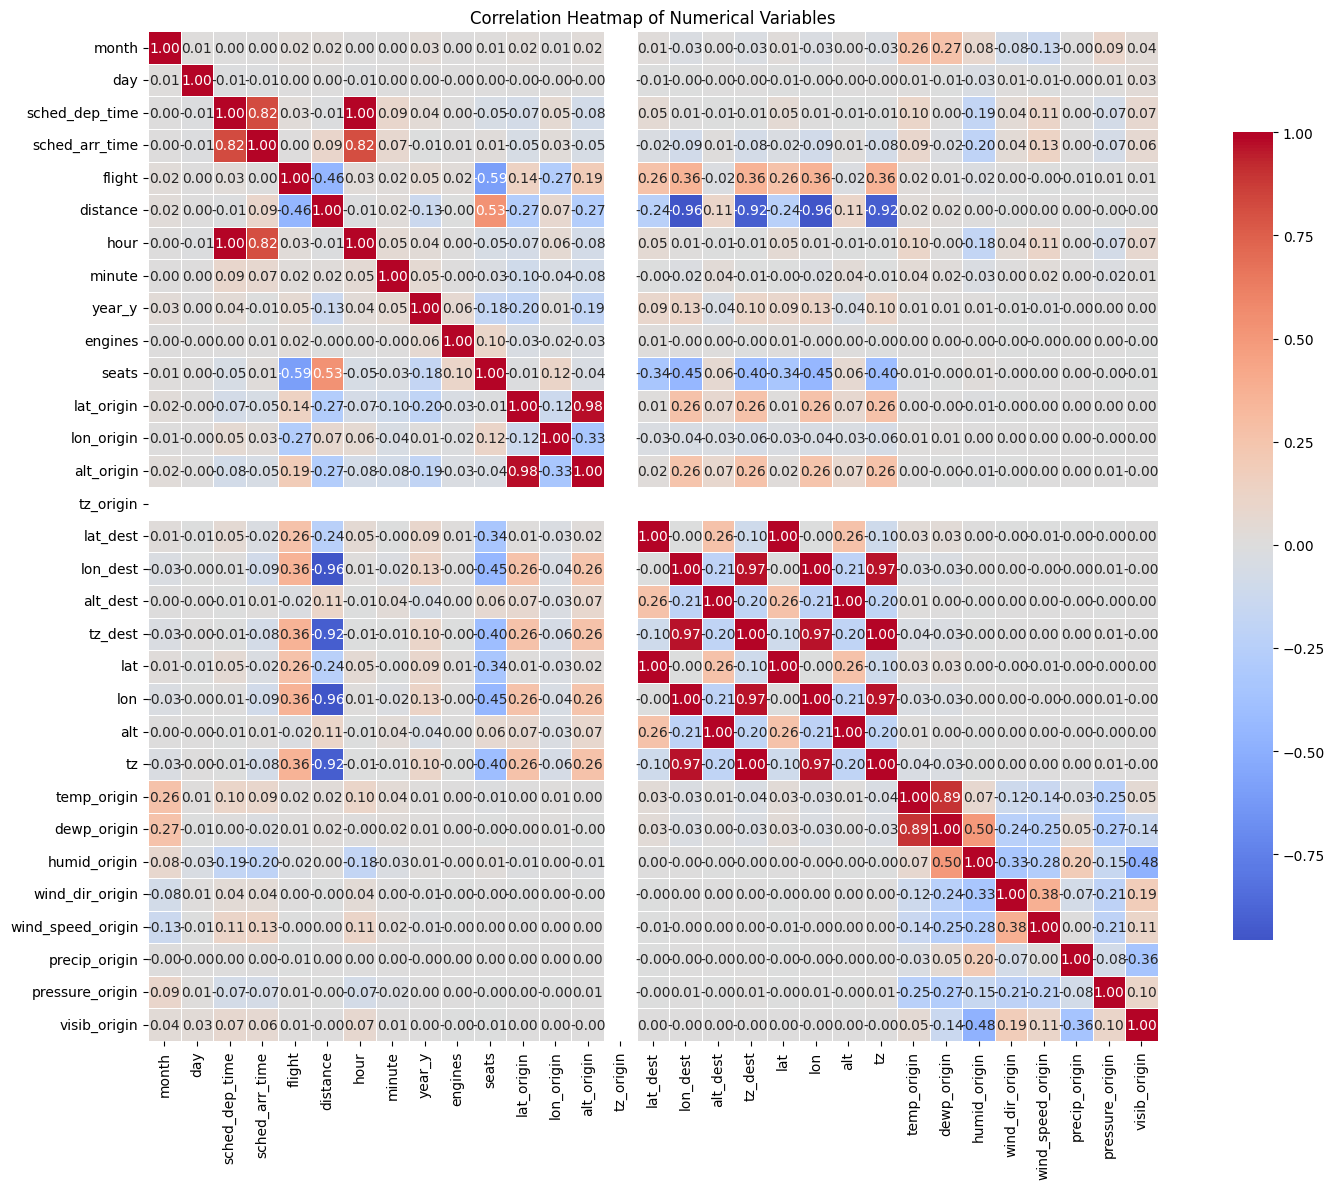

In [12]:
# Create a correlation heatmap of numerical variables
correlation_matrix = X_train.corr()

plt.figure(figsize=(16, 12))
sn.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
           square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()


In [24]:
# pipeline with scaler + XGBoost
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ('clf', XGBClassifier(objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1))
])

In [15]:
# Define parameter distributions for RandomizedSearchCV
param_dist = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [3, 5, 7, 9, 11, 15],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'clf__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__min_child_weight': [1, 3, 5, 7],
    'clf__gamma': [0, 0.1, 0.5, 1, 2],
    'clf__reg_alpha': [0, 0.1, 0.5, 1, 2],
    'clf__reg_lambda': [0.5, 1, 1.5, 2],
}

# Perform RandomizedSearchCV with extensive search
random_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=50,  # Number of parameter settings to sample
    cv=5,  # 5-fold cross-validation
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model
random_search.fit(X_train, y_train)

# Print results
print("Best parameters:", random_search.best_params_)
print("Best cross-validation score:", random_search.best_score_)

# Evaluate on test set
y_pred = random_search.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print("Test set accuracy:", test_accuracy)
  
# Display top 10 parameter combinations
results_df = pd.DataFrame(random_search.cv_results_).sort_values('rank_test_score')
print("\nTop 10 parameter combinations:")
print(results_df[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__learning_rate', 'mean_test_score', 'rank_test_score']].head(10))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'clf__subsample': 0.8, 'clf__reg_lambda': 2, 'clf__reg_alpha': 2, 'clf__n_estimators': 300, 'clf__min_child_weight': 3, 'clf__max_depth': 15, 'clf__learning_rate': 0.1, 'clf__gamma': 0.1, 'clf__colsample_bytree': 1.0}
Best cross-validation score: 0.6658495567289057
Test set accuracy: 0.8870554378328848

Top 10 parameter combinations:
    param_clf__n_estimators  param_clf__max_depth  param_clf__learning_rate  \
23                      300                    15                      0.10   
28                      300                    11                      0.20   
25                      100                    15                      0.20   
12                      100                    15                      0.20   
21                      200                    11                      0.20   
0                       200                    15                      0.05   
39                      300    

In [26]:

# Train XGBoost model with specified parameters
# Train with more estimators and deeper trees, as well as regularization to prevent overfitting
best_params = {
    'clf__subsample': 0.8,
    'clf__reg_lambda': 2,
    'clf__reg_alpha': 2,
    'clf__n_estimators': 1000,
    'clf__min_child_weight': 3,
    'clf__max_depth': 30,
    'clf__learning_rate': 0.1,
    'clf__gamma': 0.1,
    'clf__colsample_bytree': 1.0
}

# Set the parameters on the pipeline
pipeline.set_params(**best_params)

# Train the model
pipeline.fit(X_train, y_train)

# Make predictions
y_pred_xgb = pipeline.predict(X_test)

# Evaluate the model
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_proba = pipeline.predict_proba(X_test)[:, 1]
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_proba)
xgb_roc_auc = auc(xgb_fpr, xgb_tpr)
xgb_f1 = 2 * (xgb_recall * xgb_accuracy) / (xgb_recall + xgb_accuracy) if (xgb_recall + xgb_accuracy) > 0 else 0



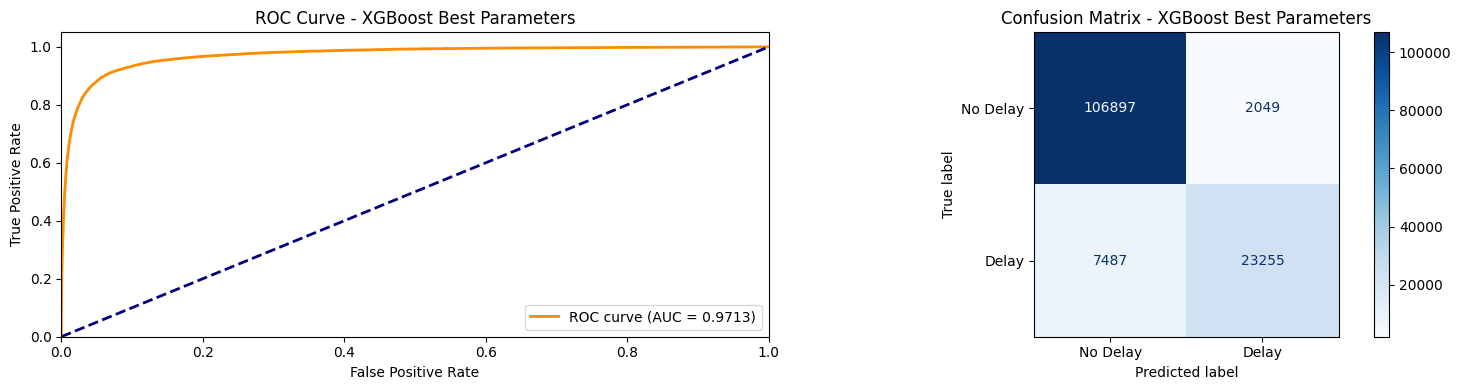

XGBoost Accuracy: 0.9317
XGBoost Recall: 0.7565
XGBoost ROC AUC: 0.9713
XGBoost F1 Score: 0.8350


In [27]:
# Calculate ROC curve with best parameters

xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_proba)
xgb_roc_auc = auc(xgb_fpr, xgb_tpr)

# Calculate confusion matrix
xgb_cm = confusion_matrix(y_test, y_pred_xgb)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ROC Curve
axes[0].plot(xgb_fpr, xgb_tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {xgb_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve - XGBoost Best Parameters')
axes[0].legend(loc="lower right")

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=xgb_cm, display_labels=['No Delay', 'Delay'])
disp.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix - XGBoost Best Parameters')

plt.tight_layout()
plt.show()

print(f"XGBoost Accuracy: {xgb_accuracy:.4f}")
print(f"XGBoost Recall: {xgb_recall:.4f}")
print(f"XGBoost ROC AUC: {xgb_roc_auc:.4f}")
print(f"XGBoost F1 Score: {xgb_f1:.4f}")

In [11]:
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))
])


In [ ]:


# Define parameter distributions for Random Forest
rf_param_dist = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [10, 15, 20, 25, 30],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__max_features': ['sqrt', 'log2'],
    'clf__bootstrap': [True, False],
}

# Perform RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=50,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model
rf_random_search.fit(X_train, y_train)

# Print results
print("Best parameters:", rf_random_search.best_params_)
print("Best cross-validation score:", rf_random_search.best_score_)

# Evaluate on test set
rf_y_pred = rf_random_search.predict(X_test)
rf_test_accuracy = accuracy_score(y_test, rf_y_pred)
print("Test set accuracy:", rf_test_accuracy)

# Display top 10 parameter combinations
rf_results_df = pd.DataFrame(rf_random_search.cv_results_).sort_values('rank_test_score')
print("\nTop 10 parameter combinations:")
print(rf_results_df[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__min_samples_split', 'mean_test_score', 'rank_test_score']].head(10))

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [14]:

# Train Random Forest model with specified parameters
best_params = {'clf__n_estimators': 1000, 
               'clf__min_samples_split': 5, 
               'clf__min_samples_leaf': 2, 
               'clf__max_features': 'sqrt', 
               'clf__max_depth': 30, 'clf__bootstrap': False}


# Set the parameters on the pipeline
rf_pipeline.set_params(**best_params)

# Train the model
rf_pipeline.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_pipeline.predict(X_test)

# Evaluate the model
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_proba = rf_pipeline.predict_proba(X_test)[:, 1]
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_proba)
rf_roc_auc = auc(rf_fpr, rf_tpr)
rf_f1 = 2 * (rf_recall * rf_accuracy) / (rf_recall + rf_accuracy) if (rf_recall + rf_accuracy) > 0 else 0

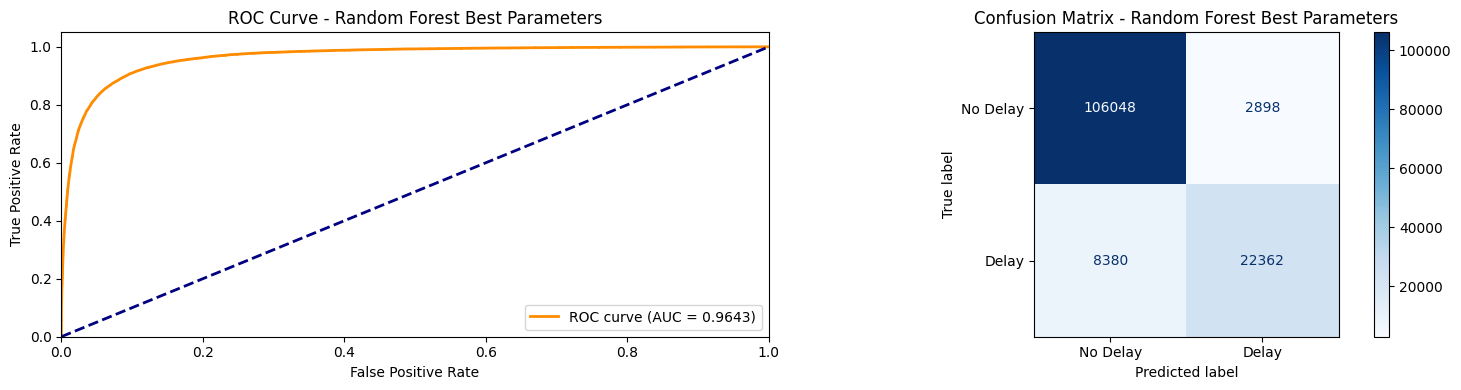

Random Forest Accuracy: 0.9193
Random Forest Recall: 0.7274
Random Forest ROC AUC: 0.9643
Random Forest F1 Score: 0.8122


In [15]:
# Calculate ROC curve with best parameters

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_proba)
rf_roc_auc = auc(rf_fpr, rf_tpr)

# Calculate confusion matrix
rf_cm = confusion_matrix(y_test, y_pred_rf)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ROC Curve
axes[0].plot(rf_fpr, rf_tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {rf_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve - Random Forest Best Parameters')
axes[0].legend(loc="lower right")

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=['No Delay', 'Delay'])
disp.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix - Random Forest Best Parameters')

plt.tight_layout()
plt.show()

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Recall: {rf_recall:.4f}")
print(f"Random Forest ROC AUC: {rf_roc_auc:.4f}")
print(f"Random Forest F1 Score: {rf_f1:.4f}")

In [16]:
# Create LightGBM pipeline
lgb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ('clf', LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1))
])

In [ ]:


# Define parameter distributions for LightGBM
lgb_param_dist = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [5, 10, 15, 20, 25],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'clf__num_leaves': [20, 31, 50, 70, 100],
    'clf__min_child_samples': [10, 20, 30, 40],
    'clf__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__reg_alpha': [0, 0.1, 0.5, 1, 2],
    'clf__reg_lambda': [0.5, 1, 1.5, 2],
}

# Perform RandomizedSearchCV
lgb_random_search = RandomizedSearchCV(
    lgb_pipeline,
    param_distributions=lgb_param_dist,
    n_iter=50,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model
lgb_random_search.fit(X_train, y_train)

# Print results
print("Best parameters:", lgb_random_search.best_params_)
print("Best cross-validation score:", lgb_random_search.best_score_)

# Evaluate on test set
lgb_y_pred = lgb_random_search.predict(X_test)
lgb_test_accuracy = accuracy_score(y_test, lgb_y_pred)
print("Test set accuracy:", lgb_test_accuracy)

# Display top 10 parameter combinations
lgb_results_df = pd.DataFrame(lgb_random_search.cv_results_).sort_values('rank_test_score')
print("\nTop 10 parameter combinations:")
print(lgb_results_df[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__learning_rate', 'mean_test_score', 'rank_test_score']].head(10))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters: {'clf__subsample': 0.9, 'clf__reg_lambda': 1.5, 'clf__reg_alpha': 0, 'clf__num_leaves': 100, 'clf__n_estimators': 500, 'clf__min_child_samples': 40, 'clf__max_depth': 20, 'clf__learning_rate': 0.2, 'clf__colsample_bytree': 0.9}
Best cross-validation score: 0.8044552461270887


C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test set accuracy: 0.9207021921992987

Top 10 parameter combinations:
    param_clf__n_estimators  param_clf__max_depth  param_clf__learning_rate  \
62                      500                    20                      0.20   
42                      400                    20                      0.20   
8                       500                    25                      0.20   
78                      500                    20                      0.15   
12                      500                    20                      0.20   
54                      400                    25                      0.10   
22                      500                    20                      0.15   
23                      400                    20                      0.20   
0                       400                    15                      0.10   
50                      300                    15                      0.15   

    mean_test_score  rank_test_score  
62         0.804455  

In [19]:

# Train XGBoost model with specified parameters
best_params = {'clf__subsample': 0.9, 
                'clf__reg_lambda': 1.5, 
                'clf__reg_alpha': 0, 
                'clf__num_leaves': 100, 
                'clf__n_estimators': 1000, 
                'clf__min_child_samples': 40, 
                'clf__max_depth': 20, 
                'clf__learning_rate': 0.2, 
                'clf__colsample_bytree': 0.9}


# Set the parameters on the pipeline
lgb_pipeline.set_params(**best_params)

# Train the model
lgb_pipeline.fit(X_train, y_train)

# Make predictions
y_pred_lgb = lgb_pipeline.predict(X_test)

# Evaluate the model
lgb_accuracy = accuracy_score(y_test, y_pred_lgb)
lgb_recall = recall_score(y_test, y_pred_lgb)
lgb_proba = lgb_pipeline.predict_proba(X_test)[:, 1]
lgb_fpr, lgb_tpr, _ = roc_curve(y_test, lgb_proba)
lgb_roc_auc = auc(lgb_fpr, lgb_tpr)
lgb_f1 = 2 * (lgb_recall * lgb_accuracy) / (lgb_recall + lgb_accuracy) if (lgb_recall + lgb_accuracy) > 0 else 0

C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


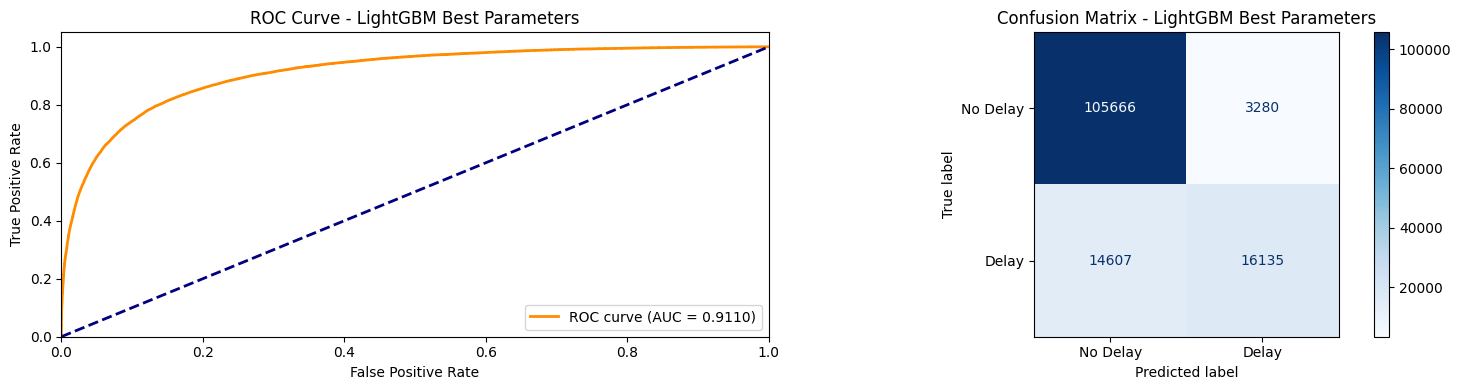

LightGBM Accuracy: 0.8720
LightGBM Recall: 0.5249
LightGBM ROC AUC: 0.9110
LightGBM F1 Score: 0.6553


In [20]:
# Calculate ROC curve with best parameters

lgb_fpr, lgb_tpr, _ = roc_curve(y_test, lgb_proba)
lgb_roc_auc = auc(lgb_fpr, lgb_tpr)

# Calculate confusion matrix
lgb_cm = confusion_matrix(y_test, y_pred_lgb)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ROC Curve
axes[0].plot(lgb_fpr, lgb_tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {lgb_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve - LightGBM Best Parameters')
axes[0].legend(loc="lower right")

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=lgb_cm, display_labels=['No Delay', 'Delay'])
disp.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix - LightGBM Best Parameters')

plt.tight_layout()
plt.show()

print(f"LightGBM Accuracy: {lgb_accuracy:.4f}")
print(f"LightGBM Recall: {lgb_recall:.4f}")
print(f"LightGBM ROC AUC: {lgb_roc_auc:.4f}")
print(f"LightGBM F1 Score: {lgb_f1:.4f}")

XGBoost ROC AUC: 0.9713, Weight: 0.3412
Random Forest ROC AUC: 0.9643, Weight: 0.3388
LightGBM ROC AUC: 0.9110, Weight: 0.3200

Ensemble Model Performance:
Accuracy: 0.9176
Recall: 0.6956
ROC AUC: 0.9650
F1 Score: 0.7913


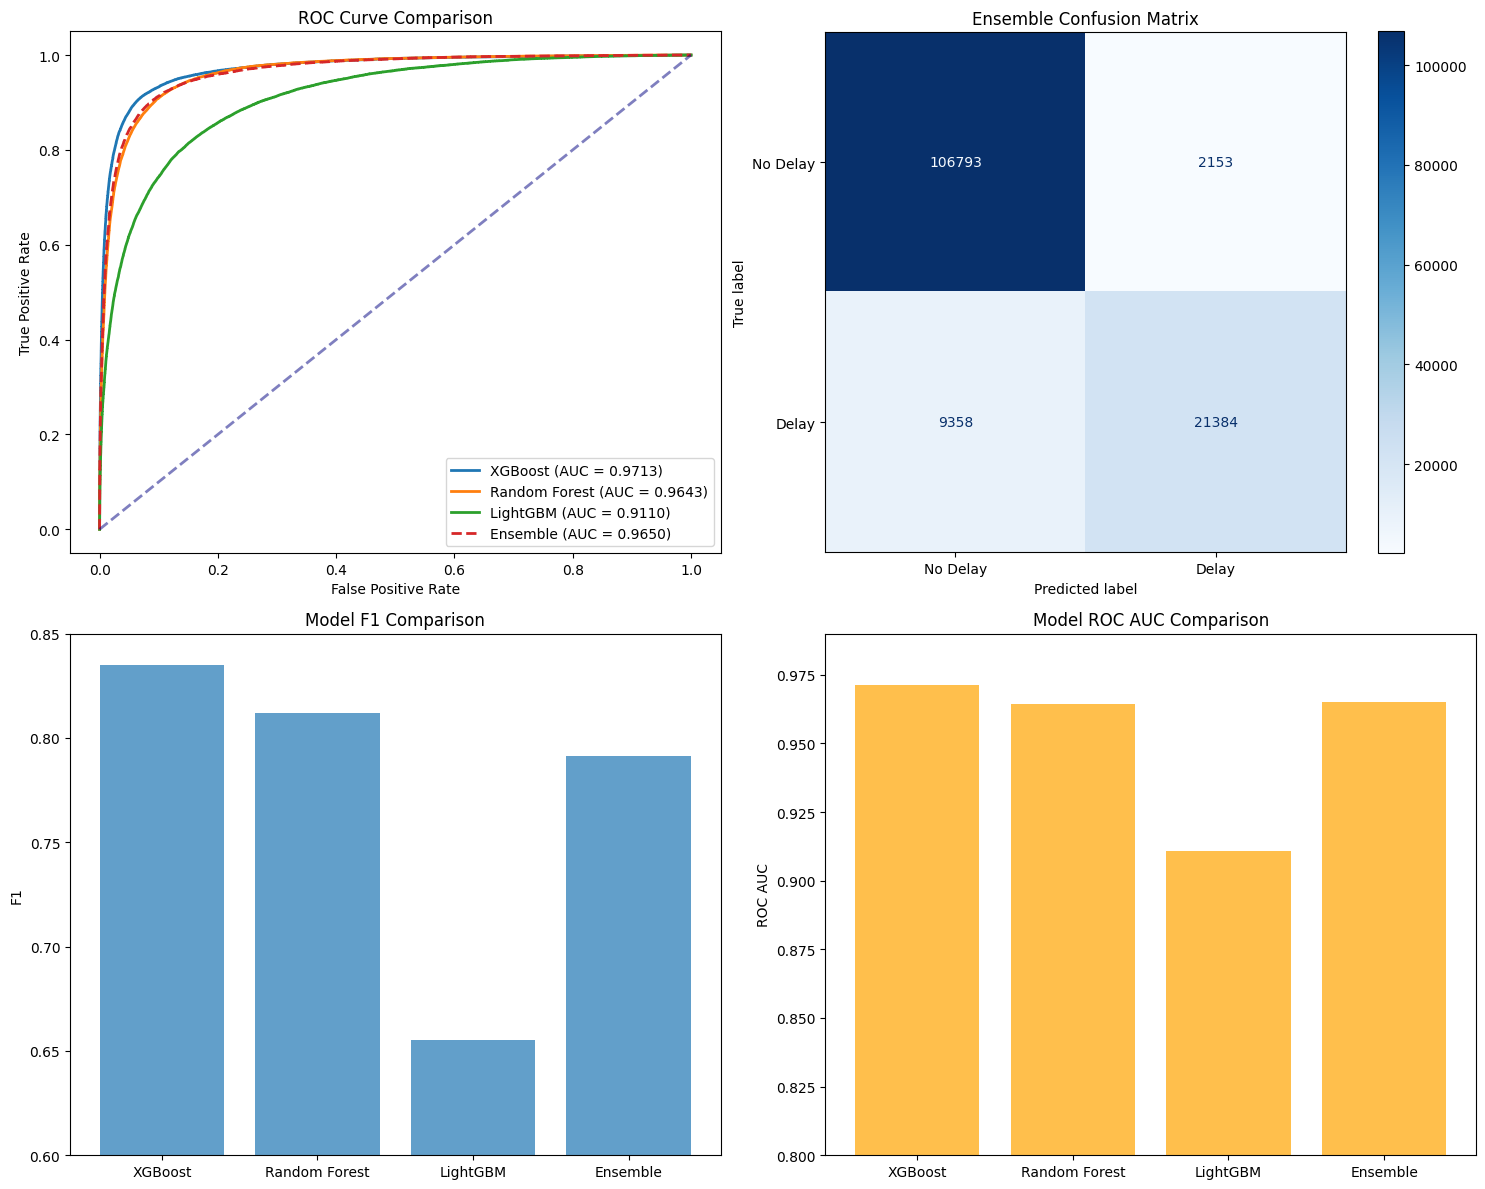


Weights used in ensemble:
XGBoost: 0.3412
Random Forest: 0.3388
LightGBM: 0.3200


In [33]:

# Calculate weights proportional to ROC AUC scores
total_auc = xgb_roc_auc + rf_roc_auc + lgb_roc_auc
w_xgb = xgb_roc_auc / total_auc
w_rf = rf_roc_auc / total_auc
w_lgb = lgb_roc_auc / total_auc

print(f"XGBoost ROC AUC: {xgb_roc_auc:.4f}, Weight: {w_xgb:.4f}")
print(f"Random Forest ROC AUC: {rf_roc_auc:.4f}, Weight: {w_rf:.4f}")
print(f"LightGBM ROC AUC: {lgb_roc_auc:.4f}, Weight: {w_lgb:.4f}")



# Weighted average ensemble prediction
ensemble_proba = (w_xgb * xgb_proba + w_rf * rf_proba + w_lgb * lgb_proba)
ensemble_pred = (ensemble_proba > 0.5).astype(int)

# Evaluate ensemble model
ensemble_accuracy = accuracy_score(y_test, ensemble_pred)
ensemble_recall = recall_score(y_test, ensemble_pred)
fpr_ens, tpr_ens, _ = roc_curve(y_test, ensemble_proba)
ensemble_roc_auc = auc(fpr_ens, tpr_ens)
ensemble_cm = confusion_matrix(y_test, ensemble_pred)

print(f"\nEnsemble Model Performance:")
print(f"Accuracy: {ensemble_accuracy:.4f}")
print(f"Recall: {ensemble_recall:.4f}")
print(f"ROC AUC: {ensemble_roc_auc:.4f}")
print(f"F1 Score: {(2 * ensemble_recall * ensemble_accuracy) / (ensemble_recall + ensemble_accuracy):.4f}")
# Plot comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# ROC Curves comparison
axes[0, 0].plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_roc_auc:.4f})', lw=2)
axes[0, 0].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_roc_auc:.4f})', lw=2)
axes[0, 0].plot(lgb_fpr, lgb_tpr, label=f'LightGBM (AUC = {lgb_roc_auc:.4f})', lw=2)
axes[0, 0].plot(fpr_ens, tpr_ens, label=f'Ensemble (AUC = {ensemble_roc_auc:.4f})', lw=2, linestyle='--')
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', alpha=0.5)
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('ROC Curve Comparison')
axes[0, 0].legend(loc="lower right")

# Ensemble Confusion Matrix
disp_ens = ConfusionMatrixDisplay(confusion_matrix=ensemble_cm, display_labels=['No Delay', 'Delay'])
disp_ens.plot(ax=axes[0, 1], cmap='Blues')
axes[0, 1].set_title('Ensemble Confusion Matrix')

# Model Comparison Bar Chart
models = ['XGBoost', 'Random Forest', 'LightGBM', 'Ensemble']
accuracies = [xgb_accuracy, rf_accuracy, lgb_accuracy, ensemble_accuracy]
auc_scores = [xgb_roc_auc, rf_roc_auc, lgb_roc_auc, ensemble_roc_auc]
test_recalls = [xgb_recall, rf_recall, lgb_recall, ensemble_recall]

f1_scores = [
    xgb_f1,
    rf_f1,
    lgb_f1,
    2 * (ensemble_accuracy * ensemble_recall) / (ensemble_accuracy + ensemble_recall) if (ensemble_accuracy + ensemble_recall) > 0 else 0
]


axes[1, 0].bar(models, f1_scores, alpha=0.7)
axes[1, 0].set_ylabel('F1')
axes[1, 0].set_title('Model F1 Comparison')
axes[1, 0].set_ylim([0.60, 0.85])

axes[1, 1].bar(models, auc_scores, alpha=0.7, color='orange')
axes[1, 1].set_ylabel('ROC AUC')
axes[1, 1].set_title('Model ROC AUC Comparison')
axes[1, 1].set_ylim([0.80, 0.99])

plt.tight_layout()
plt.show()

print(f"\nWeights used in ensemble:")
print(f"XGBoost: {w_xgb:.4f}")
print(f"Random Forest: {w_rf:.4f}")
print(f"LightGBM: {w_lgb:.4f}")

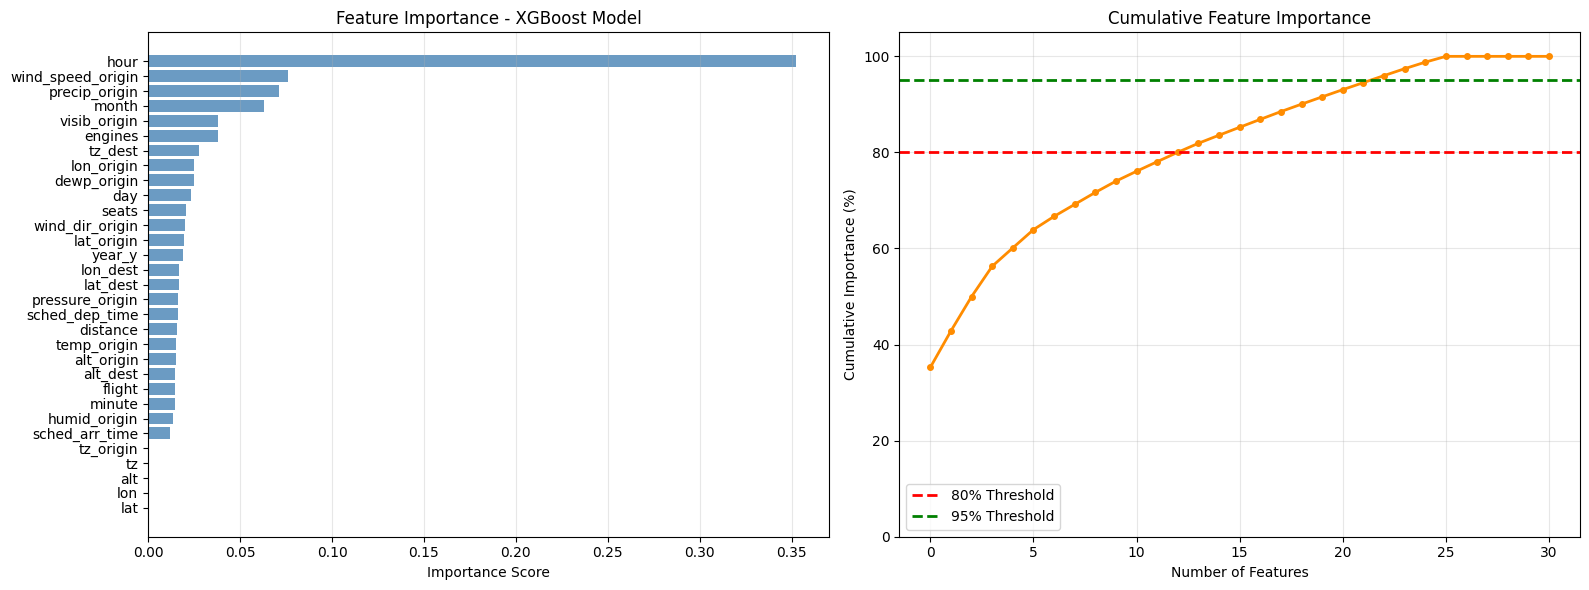

Top 15 Most Important Features:
              feature  importance  cumulative_importance_pct
6                hour    0.352469                  35.246861
27  wind_speed_origin    0.075923                  42.839123
28      precip_origin    0.071436                  49.982700
0               month    0.063161                  56.298798
30       visib_origin    0.038252                  60.124016
9             engines    0.037975                  63.921471
18            tz_dest    0.027604                  66.681892
12         lon_origin    0.025030                  69.184921
24        dewp_origin    0.024909                  71.675781
1                 day    0.023446                  74.020386
10              seats    0.020595                  76.079918
26    wind_dir_origin    0.019940                  78.073906
11         lat_origin    0.019615                  80.035416
8              year_y    0.018720                  81.907417
16           lon_dest    0.016802                  83

In [34]:
# Get feature importances from the best model (XGBoost)
feature_importance = pipeline.named_steps['clf'].feature_importances_
feature_names = X_train.columns

# Create a DataFrame for easier manipulation
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

# Calculate cumulative importance
importance_df['cumulative_importance'] = importance_df['importance'].cumsum()
importance_df['cumulative_importance_pct'] = (importance_df['cumulative_importance'] / importance_df['importance'].sum()) * 100

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Feature Importance (Bar plot)
axes[0].barh(importance_df['feature'], importance_df['importance'], color='steelblue', alpha=0.8)
axes[0].set_xlabel('Importance Score')
axes[0].set_title('Feature Importance - XGBoost Model')
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3, axis='x')

# Plot 2: Cumulative Feature Importance
axes[1].plot(range(len(importance_df)), importance_df['cumulative_importance_pct'], 
             marker='o', linewidth=2, markersize=4, color='darkorange')
axes[1].axhline(y=80, color='red', linestyle='--', linewidth=2, label='80% Threshold')
axes[1].axhline(y=95, color='green', linestyle='--', linewidth=2, label='95% Threshold')
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('Cumulative Importance (%)')
axes[1].set_title('Cumulative Feature Importance')
axes[1].grid(True, alpha=0.3)
axes[1].legend()
axes[1].set_ylim([0, 105])

plt.tight_layout()
plt.show()

# Print top 15 features
print("Top 15 Most Important Features:")
print(importance_df.head(15)[['feature', 'importance', 'cumulative_importance_pct']])

In [38]:
import subprocess

subprocess.run([
    "jupyter", "nbconvert",
    "--to", "pdf",
    "notebook.ipynb"
])

CompletedProcess(args=['jupyter', 'nbconvert', '--to', 'pdf', 'notebook.ipynb'], returncode=4294967295)